1. Load the Iris dataset and convert it into a Pandas DataFrame

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris, load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

iris = load_iris()

df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['Species'] = iris.target_names[iris.target]

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


2. Display the number of observations, features, feature names and target classes

In [2]:
print("Number of observations:", df.shape[0])
print("Number of features:", len(iris.feature_names))
print("Feature names:", iris.feature_names)
print("Target classes:", iris.target_names)

Number of observations: 150
Number of features: 4
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target classes: ['setosa' 'versicolor' 'virginica']


3. Calculate mean, standard deviation, minimum and maximum

In [3]:
stats = df.iloc[:, :4].agg(['mean', 'std', 'min', 'max'])
stats

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
max,7.900000,4.400000,6.900000,2.500000


Standardization is required to bring all features to a common scale so that features with larger values do not dominate the PCA results.

4. Apply StandardScaler

In [4]:
scaler = StandardScaler()

iris_scaled = scaler.fit_transform(iris.data)

iris_scaled_df = pd.DataFrame(
    iris_scaled,
    columns=iris.feature_names
)

iris_scaled_df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.900681,1.019004,-1.340227,-1.315444
1,-1.143017,-0.131979,-1.340227,-1.315444
2,-1.385353,0.328414,-1.397064,-1.315444
3,-1.506521,0.098217,-1.283389,-1.315444
4,-1.021849,1.249201,-1.340227,-1.315444


5. Apply PCA without specifying the number of components

In [5]:
pca = PCA()

iris_pca = pca.fit_transform(iris_scaled)

print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

Explained Variance Ratio:
[0.72962445 0.22850762 0.03668922 0.00517871]


6. Calculate cumulative explained variance

In [6]:
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

iris_variance = pd.DataFrame({
    'Principal Component': ['PC1', 'PC2', 'PC3', 'PC4'],
    'Explained Variance Ratio': pca.explained_variance_ratio_,
    'Cumulative Explained Variance': cumulative_variance
})

iris_variance

,Principal Component,Explained Variance Ratio,Cumulative Explained Variance
0,PC1,0.729624,0.729624
1,PC2,0.228508,0.958132
2,PC3,0.036689,0.994821
3,PC4,0.005179,1.000000


7. Plot explained variance ratio

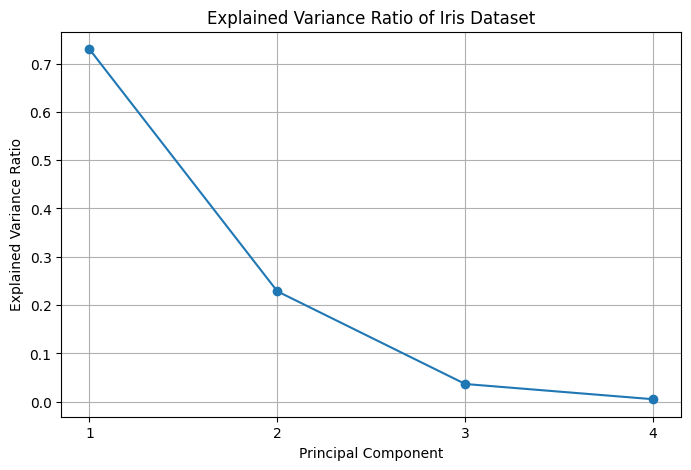

In [7]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 5),
    pca.explained_variance_ratio_,
    marker='o'
)

plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.title('Explained Variance Ratio of Iris Dataset')
plt.xticks(range(1, 5))
plt.grid()
plt.show()

8. Plot cumulative explained variance and identify minimum components

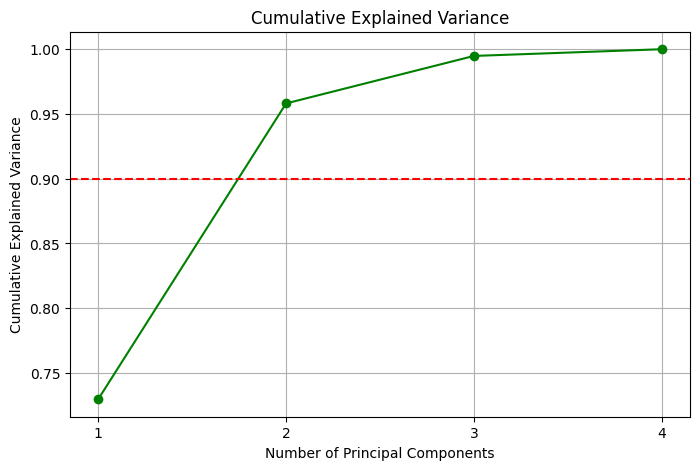

Minimum components required for 90% variance: 2


In [8]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 5),
    cumulative_variance,
    marker='o',
    color='green'
)

plt.axhline(y=0.90, color='red', linestyle='--')

plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Cumulative Explained Variance')
plt.xticks(range(1, 5))
plt.grid()
plt.show()

n_components_90 = np.argmax(cumulative_variance >= 0.90) + 1

print("Minimum components required for 90% variance:", n_components_90)

Result: The first two principal components retain approximately 95.8% of the total variance. Therefore, two components are sufficient to retain at least 90% variance.

9. Apply PCA with two principal components

In [9]:
pca_2 = PCA(n_components=2)

iris_pca_2 = pca_2.fit_transform(iris_scaled)

iris_pca_df = pd.DataFrame(
    iris_pca_2,
    columns=['PC1', 'PC2']
)

print(iris_pca_df)

print("Original dimensions:", iris_scaled.shape)
print("Reduced dimensions:", iris_pca_2.shape)

          PC1       PC2
0   -2.264703  0.480027
1   -2.080961 -0.674134
2   -2.364229 -0.341908
3   -2.299384 -0.597395
4   -2.389842  0.646835
..        ...       ...
145  1.870503  0.386966
146  1.564580 -0.896687
147  1.521170  0.269069
148  1.372788  1.011254
149  0.960656 -0.024332

[150 rows x 2 columns]
Original dimensions: (150, 4)
Reduced dimensions: (150, 2)


10. Display principal component vectors (loadings)

In [10]:
loadings = pd.DataFrame(
    pca_2.components_.T,
    columns=['PC1', 'PC2'],
    index=iris.feature_names
)

print(loadings)

print("\nMost significant features for PC1:")
print(loadings['PC1'].abs().sort_values(ascending=False))

print("\nMost significant features for PC2:")
print(loadings['PC2'].abs().sort_values(ascending=False))

                        PC1       PC2
sepal length (cm)  0.521066  0.377418
sepal width (cm)  -0.269347  0.923296
petal length (cm)  0.580413  0.024492
petal width (cm)   0.564857  0.066942

Most significant features for PC1:
petal length (cm)    0.580413
petal width (cm)     0.564857
sepal length (cm)    0.521066
sepal width (cm)     0.269347
Name: PC1, dtype: float64

Most significant features for PC2:
sepal width (cm)     0.923296
sepal length (cm)    0.377418
petal width (cm)     0.066942
petal length (cm)    0.024492
Name: PC2, dtype: float64


Result: Petal length and petal width contribute strongly to PC1. Sepal width and sepal length also contribute to PC2, with the exact contribution indicated by the absolute loading values.

11. Create a two-dimensional scatter plot

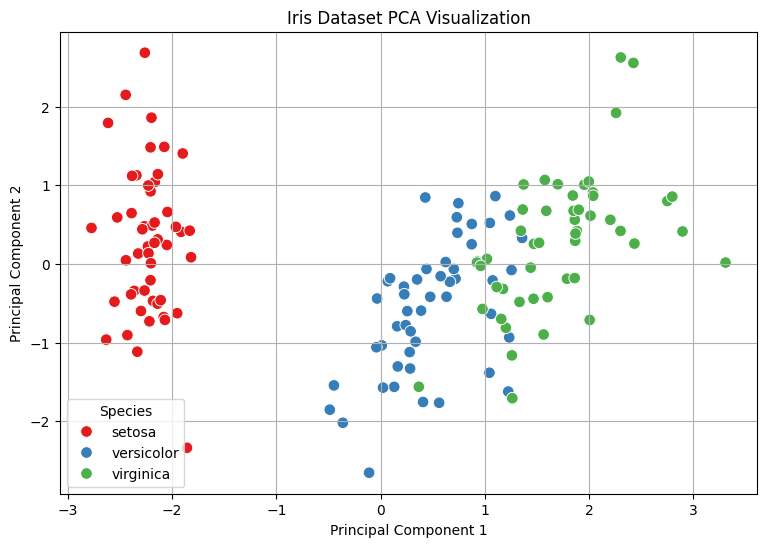

In [11]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=iris_pca_2[:, 0],
    y=iris_pca_2[:, 1],
    hue=iris.target_names[iris.target],
    palette='Set1',
    s=70
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('Iris Dataset PCA Visualization')
plt.legend(title='Species')
plt.grid()
plt.show()

12. Compare original feature space with reduced PCA space

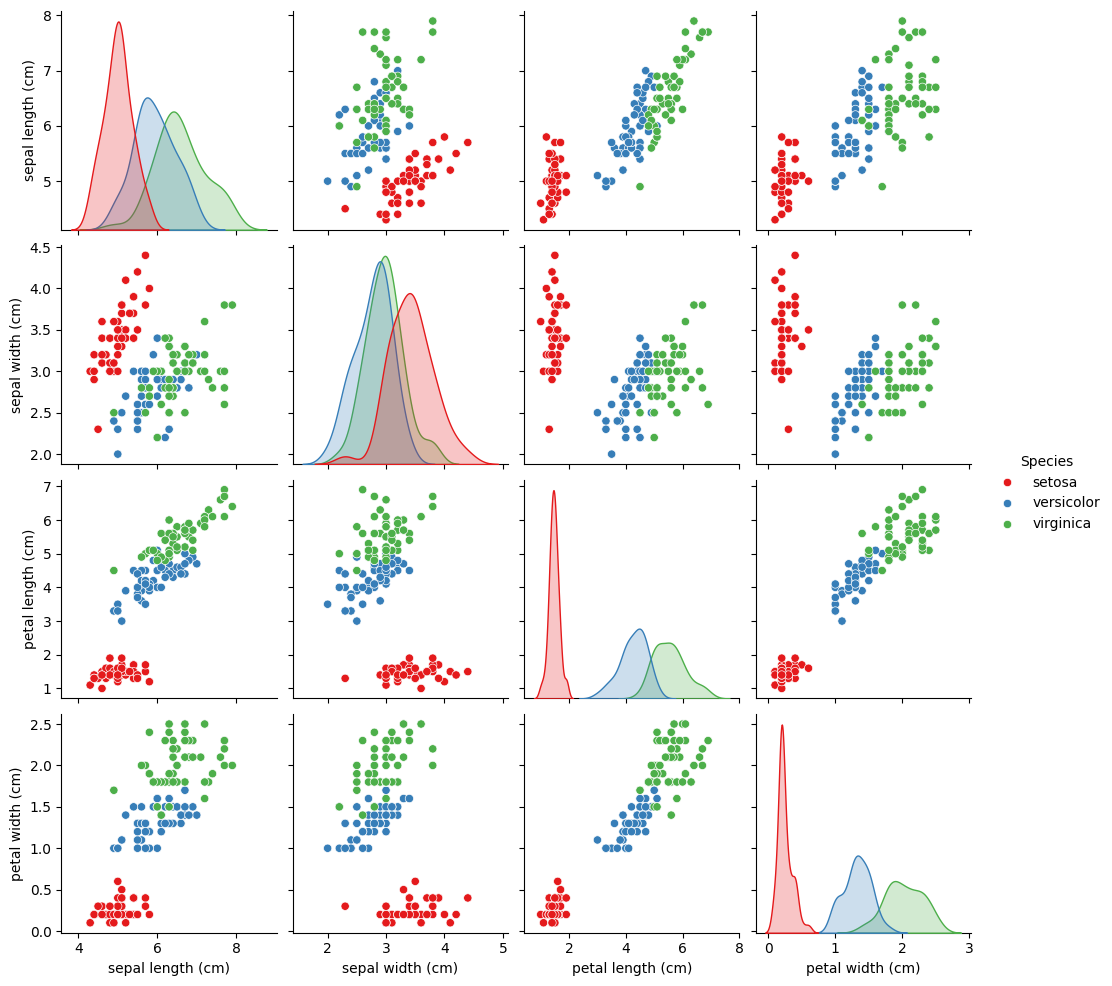

In [12]:
sns.pairplot(
    df,
    vars=iris.feature_names,
    hue='Species',
    palette='Set1'
)

plt.show()

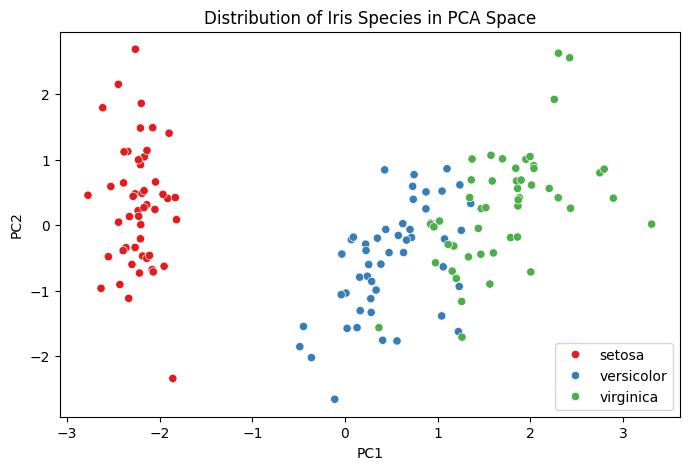

In [13]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=iris_pca_2[:, 0],
    y=iris_pca_2[:, 1],
    hue=iris.target_names[iris.target],
    palette='Set1'
)

plt.title('Distribution of Iris Species in PCA Space')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

In the original feature space, the three species show different patterns, especially in petal length and petal width. In the reduced PCA space, Setosa is clearly separated from the other two species. Versicolor and Virginica show some overlap.

13. Calculate total percentage of variance retained by two components

In [14]:
variance_retained = sum(pca_2.explained_variance_ratio_) * 100

print("Total variance retained:", variance_retained, "%")

Total variance retained: 95.81320720000166 %


Result: The first two principal components retain approximately 95.8% of the total variance.

14. Reconstruct the original standardized dataset

In [15]:
iris_reconstructed = pca_2.inverse_transform(iris_pca_2)

iris_reconstructed_df = pd.DataFrame(
    iris_reconstructed,
    columns=iris.feature_names
)

iris_reconstructed_df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.998889,1.053198,-1.302707,-1.247098
1,-1.338748,-0.061923,-1.224328,-1.220572
2,-1.360961,0.321117,-1.380603,-1.358338
3,-1.423598,0.067762,-1.349224,-1.338813
4,-1.001138,1.240918,-1.371254,-1.306618


In [16]:
iris_error = np.mean((iris_scaled - iris_reconstructed) ** 2)

print("Reconstruction Mean Squared Error:", iris_error)

Reconstruction Mean Squared Error: 0.041867927999983595


## Dataset II: Breast Cancer

1. Load the Breast Cancer dataset and convert it into a Pandas DataFrame

In [17]:
cancer = load_breast_cancer()

cancer_df = pd.DataFrame(
    cancer.data,
    columns=cancer.feature_names
)

cancer_df['Target'] = cancer.target

cancer_df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


2. Display observations, features, feature names and target classes

In [18]:
print("Number of observations:", cancer.data.shape[0])
print("Number of features:", cancer.data.shape[1])
print("Feature names:", cancer.feature_names)
print("Target classes:", cancer.target_names)

Number of observations: 569
Number of features: 30
Feature names: ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']
Target classes: ['malignant' 'benign']


Identify features having different value ranges:

In [19]:
feature_ranges = pd.DataFrame({
    'Minimum': cancer_df.iloc[:, :-1].min(),
    'Maximum': cancer_df.iloc[:, :-1].max(),
    'Range': cancer_df.iloc[:, :-1].max() - cancer_df.iloc[:, :-1].min()
})

feature_ranges.sort_values(
    by='Range',
    ascending=False
)

,Minimum,Maximum,Range
worst area,185.200000,4254.00000,4068.800000
mean area,143.500000,2501.00000,2357.500000
area error,6.802000,542.20000,535.398000
worst perimeter,50.410000,251.20000,200.790000
mean perimeter,43.790000,188.50000,144.710000
worst texture,12.020000,49.54000,37.520000
mean texture,9.710000,39.28000,29.570000
worst radius,7.930000,36.04000,28.110000
perimeter error,0.757000,21.98000,21.223000
mean radius,6.981000,28.11000,21.129000


4. Check missing values and duplicate records

In [20]:
print("Missing values:")
print(cancer_df.isnull().sum())

print("\nTotal missing values:")
print(cancer_df.isnull().sum().sum())

print("\nDuplicate records:")
print(cancer_df.duplicated().sum())

Missing values:
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
Target                     0
dtype: int64

Total missing values:
0

Duplicate records:
0


5. Apply StandardScaler

In [21]:
cancer_scaler = StandardScaler()

cancer_scaled = cancer_scaler.fit_transform(cancer.data)

cancer_scaled_df = pd.DataFrame(
    cancer_scaled,
    columns=cancer.feature_names
)

cancer_scaled_df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,1.097064,-2.073335,1.269934,0.984375,1.568466,3.283515,2.652874,2.532475,2.217515,2.255747,...,1.886690,-1.359293,2.303601,2.001237,1.307686,2.616665,2.109526,2.296076,2.750622,1.937015
1,1.829821,-0.353632,1.685955,1.908708,-0.826962,-0.487072,-0.023846,0.548144,0.001392,-0.868652,...,1.805927,-0.369203,1.535126,1.890489,-0.375612,-0.430444,-0.146749,1.087084,-0.243890,0.281190
2,1.579888,0.456187,1.566503,1.558884,0.942210,1.052926,1.363478,2.037231,0.939685,-0.398008,...,1.511870,-0.023974,1.347475,1.456285,0.527407,1.082932,0.854974,1.955000,1.152255,0.201391
3,-0.768909,0.253732,-0.592687,-0.764464,3.283553,3.402909,1.915897,1.451707,2.867383,4.910919,...,-0.281464,0.133984,-0.249939,-0.550021,3.394275,3.893397,1.989588,2.175786,6.046041,4.935010
4,1.750297,-1.151816,1.776573,1.826229,0.280372,0.539340,1.371011,1.428493,-0.009560,-0.562450,...,1.298575,-1.466770,1.338539,1.220724,0.220556,-0.313395,0.613179,0.729259,-0.868353,-0.397100


6. Apply PCA without specifying the number of components

In [22]:
cancer_pca = PCA()

cancer_pca_result = cancer_pca.fit_transform(cancer_scaled)

print("Explained Variance Ratio:")
print(cancer_pca.explained_variance_ratio_)

Explained Variance Ratio:
[4.42720256e-01 1.89711820e-01 9.39316326e-02 6.60213492e-02
 5.49576849e-02 4.02452204e-02 2.25073371e-02 1.58872380e-02
 1.38964937e-02 1.16897819e-02 9.79718988e-03 8.70537901e-03
 8.04524987e-03 5.23365745e-03 3.13783217e-03 2.66209337e-03
 1.97996793e-03 1.75395945e-03 1.64925306e-03 1.03864675e-03
 9.99096464e-04 9.14646751e-04 8.11361259e-04 6.01833567e-04
 5.16042379e-04 2.72587995e-04 2.30015463e-04 5.29779290e-05
 2.49601032e-05 4.43482743e-06]


7. Calculate cumulative explained variance for all 30 components

In [23]:
cancer_cumulative = np.cumsum(
    cancer_pca.explained_variance_ratio_
)

cancer_variance_df = pd.DataFrame({
    'Principal Component': range(1, 31),
    'Explained Variance Ratio': cancer_pca.explained_variance_ratio_,
    'Cumulative Explained Variance': cancer_cumulative
})

cancer_variance_df

,Principal Component,Explained Variance Ratio,Cumulative Explained Variance
0,1,0.442720,0.442720
1,2,0.189712,0.632432
2,3,0.093932,0.726364
3,4,0.066021,0.792385
4,5,0.054958,0.847343
5,6,0.040245,0.887588
6,7,0.022507,0.910095
7,8,0.015887,0.925983
8,9,0.013896,0.939879
9,10,0.011690,0.951569


8. Plot explained variance ratio

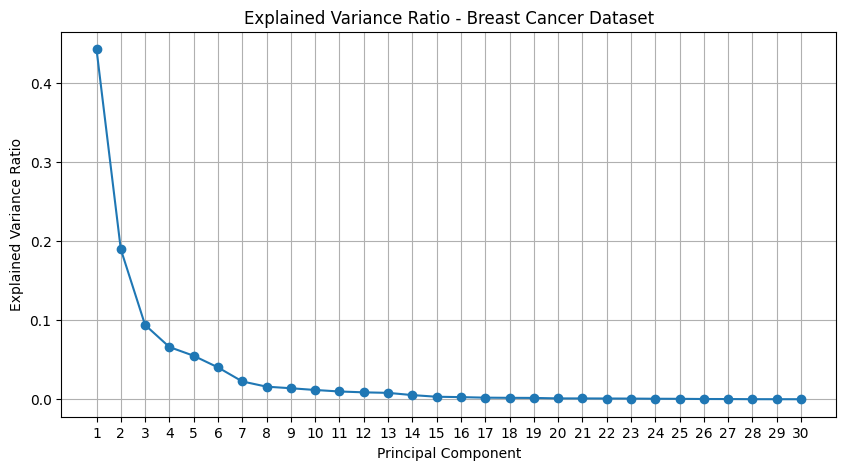

In [24]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, 31),
    cancer_pca.explained_variance_ratio_,
    marker='o'
)

plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.title('Explained Variance Ratio - Breast Cancer Dataset')
plt.xticks(range(1, 31))
plt.grid()
plt.show()

9. Plot cumulative explained variance and identify minimum components

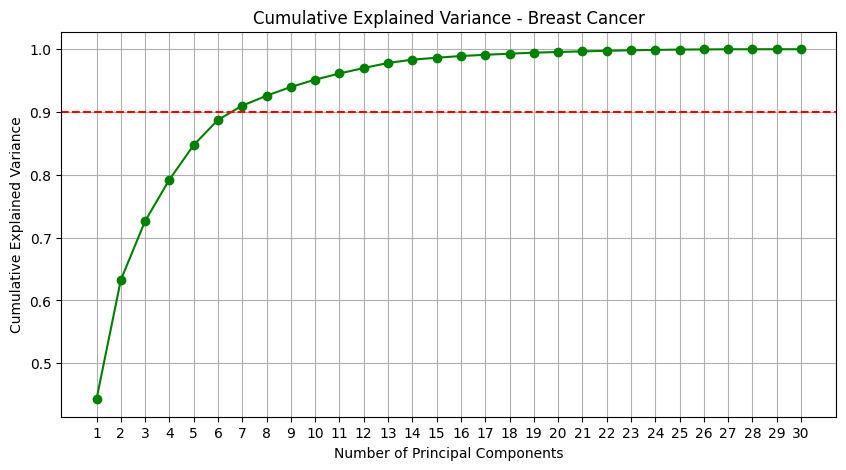

Minimum components required for 90% variance: 7


In [25]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, 31),
    cancer_cumulative,
    marker='o',
    color='green'
)

plt.axhline(y=0.90, color='red', linestyle='--')

plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Cumulative Explained Variance - Breast Cancer')
plt.xticks(range(1, 31))
plt.grid()
plt.show()

n_components_90_cancer = np.argmax(
    cancer_cumulative >= 0.90
) + 1

print(
    "Minimum components required for 90% variance:",
    n_components_90_cancer
)

10. Apply PCA retaining only two principal components

In [26]:
cancer_pca_2 = PCA(n_components=2)

cancer_pca_2_result = cancer_pca_2.fit_transform(
    cancer_scaled
)

cancer_pca_2_df = pd.DataFrame(
    cancer_pca_2_result,
    columns=['PC1', 'PC2']
)

print(cancer_pca_2_df)

print("Original dimensions:", cancer_scaled.shape)
print("Reduced dimensions:", cancer_pca_2_result.shape)

           PC1        PC2
0     9.192837   1.948583
1     2.387802  -3.768172
2     5.733896  -1.075174
3     7.122953  10.275589
4     3.935302  -1.948072
..         ...        ...
564   6.439315  -3.576817
565   3.793382  -3.584048
566   1.256179  -1.902297
567  10.374794   1.672010
568  -5.475243  -0.670637

[569 rows x 2 columns]
Original dimensions: (569, 30)
Reduced dimensions: (569, 2)


11. Display principal component vectors (loadings)

In [27]:
cancer_loadings = pd.DataFrame(
    cancer_pca_2.components_.T,
    columns=['PC1', 'PC2'],
    index=cancer.feature_names
)

print(cancer_loadings)

print("\nMost significant features for PC1:")
print(
    cancer_loadings['PC1'].abs().sort_values(
        ascending=False
    )
)

print("\nMost significant features for PC2:")
print(
    cancer_loadings['PC2'].abs().sort_values(
        ascending=False
    )
)

                              PC1       PC2
mean radius              0.218902 -0.233857
mean texture             0.103725 -0.059706
mean perimeter           0.227537 -0.215181
mean area                0.220995 -0.231077
mean smoothness          0.142590  0.186113
mean compactness         0.239285  0.151892
mean concavity           0.258400  0.060165
mean concave points      0.260854 -0.034768
mean symmetry            0.138167  0.190349
mean fractal dimension   0.064363  0.366575
radius error             0.205979 -0.105552
texture error            0.017428  0.089980
perimeter error          0.211326 -0.089457
area error               0.202870 -0.152293
smoothness error         0.014531  0.204430
compactness error        0.170393  0.232716
concavity error          0.153590  0.197207
concave points error     0.183417  0.130322
symmetry error           0.042498  0.183848
fractal dimension error  0.102568  0.280092
worst radius             0.227997 -0.219866
worst texture            0.10446

12. Create a two-dimensional scatter plot

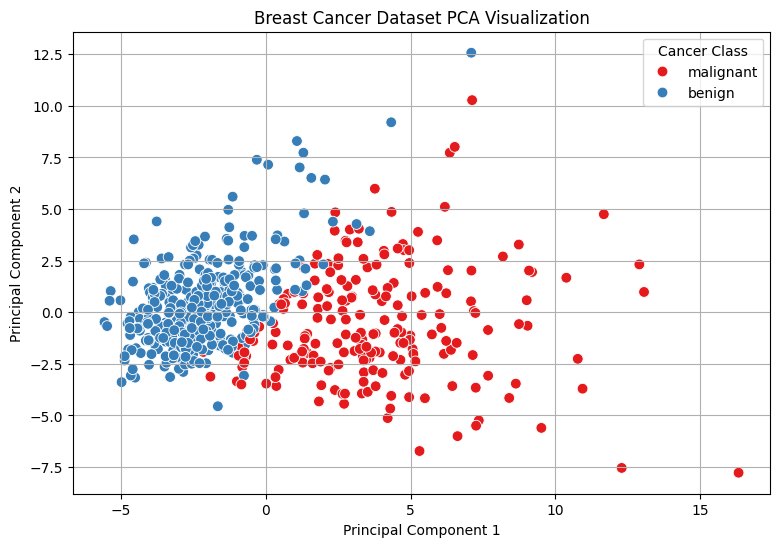

In [28]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=cancer_pca_2_result[:, 0],
    y=cancer_pca_2_result[:, 1],
    hue=cancer.target_names[cancer.target],
    palette='Set1',
    s=60
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('Breast Cancer Dataset PCA Visualization')
plt.legend(title='Cancer Class')
plt.grid()
plt.show()

13. Observe the distribution of malignant and benign samples

In [29]:
cancer_variance_retained = (
    np.sum(cancer_pca_2.explained_variance_ratio_) * 100
)

print(
    "Variance retained by two components:",
    cancer_variance_retained,
    "%"
)

Variance retained by two components: 63.243207651559445 %


15. Reconstruct the standardized dataset using two components and calculate reconstruction error

In [30]:
cancer_reconstructed_2 = cancer_pca_2.inverse_transform(
    cancer_pca_2_result
)

cancer_reconstructed_2_df = pd.DataFrame(
    cancer_reconstructed_2,
    columns=cancer.feature_names
)

print(cancer_reconstructed_2_df.head())

error_2 = np.mean(
    (cancer_scaled - cancer_reconstructed_2) ** 2
)

print("Reconstruction error using 2 components:", error_2)

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0     1.556644      0.837181        1.672414   1.581299         1.673460   
1     1.403909      0.472657        1.354154   1.398429        -0.360830   
2     1.506601      0.658940        1.536033   1.515610         0.617491   
3    -0.843788      0.125310       -0.590378  -0.800312         2.928081   
4     1.317018      0.524499        1.314617   1.319836         0.198572   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0          2.495685        2.492671             2.330239       1.641057   
1         -0.000988        0.390296             0.753877      -0.387352   
2          1.208728        1.416953             1.533090       0.587577   
3          3.265194        2.458809             1.500793       2.940103   
4          0.645764        0.899678             1.094268       0.172916   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
0           

16. Repeat reconstruction using the minimum components required for 90% variance

In [31]:
cancer_pca_90 = PCA(
    n_components=n_components_90_cancer
)

cancer_pca_90_result = cancer_pca_90.fit_transform(
    cancer_scaled
)

cancer_reconstructed_90 = cancer_pca_90.inverse_transform(
    cancer_pca_90_result
)

cancer_reconstructed_90_df = pd.DataFrame(
    cancer_reconstructed_90,
    columns=cancer.feature_names
)

print(cancer_reconstructed_90_df.head())

error_90 = np.mean(
    (cancer_scaled - cancer_reconstructed_90) ** 2
)

print(
    "Reconstruction error using",
    n_components_90_cancer,
    "components:",
    error_90
)

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0     1.430035     -1.388322        1.567996   1.616678         2.098120   
1     1.477105     -0.267407        1.428238   1.448671        -0.364485   
2     1.635444      0.057014        1.658707   1.580173         0.823988   
3    -1.041984     -0.110844       -0.775366  -0.995154         3.294964   
4     1.540777     -1.157396        1.531510   1.573174         0.805640   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0          2.727267        2.210494             2.250371       2.596169   
1          0.081068        0.462235             0.809697      -0.472256   
2          1.248224        1.484373             1.686918       0.980921   
3          3.475976        2.014865             1.349161       4.940447   
4          0.631075        1.119058             1.431611      -0.202183   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
0           

Compare reconstruction errors

In [32]:
comparison = pd.DataFrame({
    'Method': [
        'PCA with 2 Components',
        'PCA with 90% Variance Components'
    ],
    'Number of Components': [
        2,
        n_components_90_cancer
    ],
    'Reconstruction Error': [
        error_2,
        error_90
    ]
})

comparison

,Method,Number of Components,Reconstruction Error
0,PCA with 2 Components,2,0.367568
1,PCA with 90% Variance Components,7,0.089905


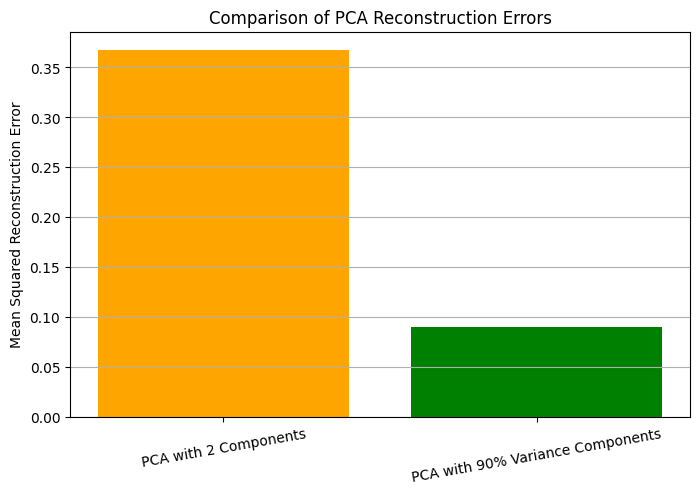

In [33]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison['Method'],
    comparison['Reconstruction Error'],
    color=['orange', 'green']
)

plt.ylabel('Mean Squared Reconstruction Error')
plt.title('Comparison of PCA Reconstruction Errors')
plt.xticks(rotation=10)
plt.grid(axis='y')
plt.show()